# Small Business Loan Analysis

The Small Business Administration releases public records under FOIA (Freedom of Information Act) regarding it's 7(a) loan program. An SBA 7(a) loan is the quarterback small business financing program offered by private lenders which are backed by the 
U.S. SBA Administration. The federal government guarantees a portion of the loan in order to reduce the financial risk for financial institutions, which incentivizes them to extend captial to small business that might not qualify for traditional loans. 7(a) loans, maxxed up to $5 million, is a general-purpose, flexible option used fore operational costs, working captial, and growing your business. This is constrasted with another SBA loan, the 504 loan, which is a specialized long-term tool specifically for large investments like commercial real estate and heavy machinery.

## CRISP-DM: Data Understanding

#### PART 1: Collect Initial Data



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##### First data look

I am loading in the FOIA 7(a) loan data presented by the SBA. This is a description of small business 7(a) loans only from 2020 to the present. It appears we have ~338,000 and 42 columns.

**Problem**

If I am going to build a classification model with no external data, I will need enough data for a model to produce real connections. Within my dataset thee are five categories for loan status. The two that I need for this model are CHGOFF (default) and PIF (paid in full), but this data contains mainly active loans: 
LoanStatus
EXEMPT    242061
PIF        68201
CANCLD     50104
COMMIT     21079
CHGOFF      6893

**Solution** 

You can see that I will lose a lot of information with only PIF and CHGOFF, so I will have to enter new data into my environment. Currently I have 2020-2026 data; I will need to include the 2010-2019 data which adds ~500,000 rows to my data.

In [2]:
from pathlib import Path

# Load the raw dataset using a path relative to the project root.
data_path = Path("../data/raw/FOIA_7a_FY2020_Present_asof_260630.csv")
df = pd.read_csv(data_path, low_memory=False)

# Remove spaces and commas from every string value while preserving missing values.
string_columns = df.select_dtypes(include=["object", "string"]).columns
for column in string_columns:
    df[column] = df[column].str.replace(r"[\s,]+", "", regex=True)

# Clean column names as well, so they contain no spaces or commas.
df.columns = df.columns.str.replace(r"[\s,]+", "", regex=True)

print(f"Loaded {len(df):,} rows and {len(df.columns)} columns")
print("Cleaned string columns:", list(string_columns))
print("Remaining spaces or commas in string values:", sum(
    df[column].astype("string").str.contains(r"[\s,]", regex=True, na=False).sum()
    for column in df.select_dtypes(include=["object", "string"]).columns
))
print(df.info())


Loaded 388,338 rows and 42 columns
Cleaned string columns: ['AsOfDate', 'Program', 'BorrName', 'BorrStreet', 'BorrCity', 'BorrState', 'BankName', 'BankStreet', 'BankCity', 'BankState', 'ApprovalDate', 'FirstDisbursementDate', 'ProcessingMethod', 'FixedorVariableInterestInd', 'NaicsDescription', 'FranchiseCode', 'FranchiseName', 'ProjectCounty', 'ProjectState', 'SBADistrictOffice', 'BusinessType', 'BusinessAge', 'LoanStatus', 'PaidInFullDate', 'ChargeOffDate', 'RevolverStatus', 'CollateralInd', 'SoldSecMrktInd']
Remaining spaces or commas in string values: 0
<class 'pandas.DataFrame'>
RangeIndex: 388338 entries, 0 to 388337
Data columns (total 42 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AsOfDate                    388338 non-null  str    
 1   Program                     388338 non-null  str    
 2   LocationID                  388338 non-null  int64  
 3   BorrName                    388336 non-nu

In [3]:
print(df['LoanStatus'].value_counts())

LoanStatus
EXEMPT    242061
PIF        68201
CANCLD     50104
COMMIT     21079
CHGOFF      6893
Name: count, dtype: int64


In [4]:
from pathlib import Path

# Load the raw dataset using a path relative to the project root.
data_path = Path("../data/raw/FOIA_7a_FY2010_FY2019_asof_260630.csv")
df2 = pd.read_csv(data_path, low_memory=False)

# Remove spaces and commas from every string value while preserving missing values.
string_columns = df2.select_dtypes(include=["object", "string"]).columns
for column in string_columns:
    df2[column] = df2[column].str.replace(r"[\s,]+", "", regex=True)

# Clean column names as well, so they contain no spaces or commas.
df2.columns = df2.columns.str.replace(r"[\s,]+", "", regex=True)

print(f"Loaded {len(df2):,} rows and {len(df2.columns)} columns")
print("Cleaned string columns:", list(string_columns))
print("Remaining spaces or commas in string values:", sum(
    df2[column].astype("string").str.contains(r"[\s,]", regex=True, na=False).sum()
    for column in df2.select_dtypes(include=["object", "string"]).columns
))
print(df2.describe(include="all"))

Loaded 545,751 rows and 42 columns
Cleaned string columns: ['AsOfDate', 'Program', 'BorrName', 'BorrStreet', 'BorrCity', 'BorrState', 'BankName', 'BankStreet', 'BankCity', 'BankState', 'BankZip', 'ApprovalDate', 'FirstDisbursementDate', 'ProcessingMethod', 'FixedorVariableInterestInd', 'NaicsDescription', 'FranchiseCode', 'FranchiseName', 'ProjectCounty', 'ProjectState', 'SBADistrictOffice', 'BusinessType', 'BusinessAge', 'LoanStatus', 'PaidInFullDate', 'ChargeOffDate', 'RevolverStatus', 'CollateralInd', 'SoldSecMrktInd']
Remaining spaces or commas in string values: 0
          AsOfDate Program     LocationID               BorrName BorrStreet  \
count       545751  545751  545750.000000                 545721     545751   
unique           1       1            NaN                 432362     471656   
top     2026-06-30      7A            NaN  TheCoveatRiverOaksLLC        TBD   
freq        545751  545751            NaN                     42         62   
mean           NaN     NaN  10

In [5]:
print('#' * 62)
print('DATA COMPARISON CHECK')
print('#' * 62)
print('\n')
print('2020-Present Data')

print(df['LoanStatus'].value_counts(dropna=False))
print(f'Total Rows: {len(df)}')
print('\n')
print('2010-2019 Data')
print(df2['LoanStatus'].value_counts(dropna=False))
print(f'Total Rows: {len(df2)}')

##############################################################
DATA COMPARISON CHECK
##############################################################


2020-Present Data
LoanStatus
EXEMPT    242061
PIF        68201
CANCLD     50104
COMMIT     21079
CHGOFF      6893
Name: count, dtype: int64
Total Rows: 388338


2010-2019 Data
LoanStatus
PIF       394721
CANCLD     66744
EXEMPT     50089
CHGOFF     34153
COMMIT        44
Name: count, dtype: int64
Total Rows: 545751


In [6]:
df_full = pd.concat([df,df2], ignore_index = True)

print(f'Total Rows: {len(df_full)}')
df_full.head()

Total Rows: 934089


,AsOfDate,Program,LocationID,BorrName,BorrStreet,BorrCity,BorrState,BorrZip,BankName,BankFDICNumber,...,BusinessType,BusinessAge,LoanStatus,PaidInFullDate,ChargeOffDate,GrossChargeOffAmount,RevolverStatus,JobsSupported,CollateralInd,SoldSecMrktInd
0,6/30/2026,7A,29805.0,AMERIPROCONSTRUCTIONSERVICESINC.,1403SENTRYLANE,Norristown,PA,19403,TDBankNationalAssociation,18409.0,...,PARTNERSHIP,Unanswered,PIF,11/30/2024,NaN,0.0,Y,5.0,N,NaN
1,6/30/2026,7A,84894.0,MeluotaCorp,2702ASTORIABLVD,ASTORIA,NY,11102,SantanderBankNationalAssociation,29950.0,...,CORPORATION,Existingormorethan2yearsold,PIF,11/30/2023,NaN,0.0,Y,3.0,N,NaN
2,6/30/2026,7A,53803.0,THOMASWCHASE,1700GIDGETLN,COLFAX,CA,95713,U.S.BankNationalAssociation,6548.0,...,INDIVIDUAL,Unanswered,PIF,11/30/2024,NaN,0.0,N,0.0,Y,NaN
3,6/30/2026,7A,123499.0,513SOLUTIONSGROUPLLC,120FIREBIRDRUN,CIBOLO,TX,78108,BayFirstNationalBank,34997.0,...,CORPORATION,Existingormorethan2yearsold,EXEMPT,NaN,NaN,0.0,N,3.0,N,Y
4,6/30/2026,7A,70400.0,TianShanInternationalLLC,2503BAGBYST,HOUSTON,TX,77006,GoldenBankNationalAssociation,26223.0,...,CORPORATION,Unanswered,PIF,1/31/2024,NaN,0.0,N,4.0,Y,NaN


This concludes part 1 of data understandint, collect initial data.

#### Part 2: Describe Data

The next piece of the Data Understanding of the CRISP-DM framwework is to continue to explore my data and begin to understand just how it will be used for modeling and other analysis.

**Problem 1**

If I want LoanStatus to turn into my target variable, I will need to extract my two outcome, PIF and CHGOFF, the following cells do this.

In [7]:
print(len(df_full))

934089


In [8]:
status_bucket_map = {
    'PIF': 'success',
    'CHGOFF': 'default',
    'EXEMPT': 'active',       
    'COMMIT': 'not_disbursed',
    'CANCLD': 'not_disbursed',
}

df_full['outcome_bucket'] = df_full['LoanStatus'].str.strip().map(status_bucket_map)



unmapped = df_full.loc[df_full['outcome_bucket'].isna(), 'LoanStatus'].value_counts()

if len(unmapped) > 0:
    print("unmapped LoanStatus values found")
    print(unmapped)
df_model = df_full[df_full['outcome_bucket'].isin(['success', 'default'])].copy()
df_model['target'] = (df_model['outcome_bucket'] == 'success').astype(int)

print(df_model['outcome_bucket'].value_counts())
print(f"Usable rows for modeling: {len(df_model)} of {len(df_full)} total ({len(df_model)/len(df_full):.1%})")

outcome_bucket
success    462922
default     41046
Name: count, dtype: int64
Usable rows for modeling: 503968 of 934089 total (54.0%)


In [9]:
df_model.head()

,AsOfDate,Program,LocationID,BorrName,BorrStreet,BorrCity,BorrState,BorrZip,BankName,BankFDICNumber,...,LoanStatus,PaidInFullDate,ChargeOffDate,GrossChargeOffAmount,RevolverStatus,JobsSupported,CollateralInd,SoldSecMrktInd,outcome_bucket,target
0,6/30/2026,7A,29805.0,AMERIPROCONSTRUCTIONSERVICESINC.,1403SENTRYLANE,Norristown,PA,19403,TDBankNationalAssociation,18409.0,...,PIF,11/30/2024,NaN,0.0,Y,5.0,N,NaN,success,1
1,6/30/2026,7A,84894.0,MeluotaCorp,2702ASTORIABLVD,ASTORIA,NY,11102,SantanderBankNationalAssociation,29950.0,...,PIF,11/30/2023,NaN,0.0,Y,3.0,N,NaN,success,1
2,6/30/2026,7A,53803.0,THOMASWCHASE,1700GIDGETLN,COLFAX,CA,95713,U.S.BankNationalAssociation,6548.0,...,PIF,11/30/2024,NaN,0.0,N,0.0,Y,NaN,success,1
4,6/30/2026,7A,70400.0,TianShanInternationalLLC,2503BAGBYST,HOUSTON,TX,77006,GoldenBankNationalAssociation,26223.0,...,PIF,1/31/2024,NaN,0.0,N,4.0,Y,NaN,success,1
8,6/30/2026,7A,58036.0,L.N.ZimmermannInc.,7790MainlandDrSte101,SanAntonio,TX,78250,FifthThirdBank,6672.0,...,PIF,9/30/2021,NaN,0.0,Y,0.0,Y,NaN,success,1


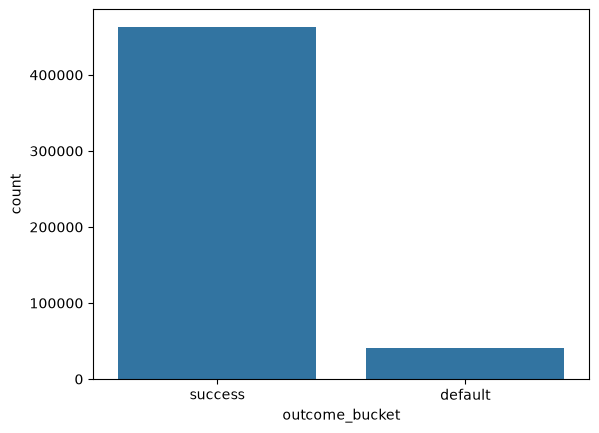

In [10]:
sns.countplot(df_model, x='outcome_bucket', )
plt.show()

**Problem 2**

We can see that we have a huge class imbalance, so I can guarantee that accuracy will not be the right metric in a classification model. I will need to utilize ROC-AUC/Precision-Recall, class weighting or resampling. 

In [11]:
df_model['outcome_bucket'].value_counts()

outcome_bucket
success    462922
default     41046
Name: count, dtype: int64

In [12]:
name = ['NaicsDescription','BusinessType','BusinessAge','LoanStatus','PaidInFullDate','ChargeOffDate','GrossChargeOffAmount','RevolverStatus']

for i in name:
    print(f'{i} : ', df_model[i].isnull().sum())

NaicsDescription :  3
BusinessType :  19
BusinessAge :  1343
LoanStatus :  0
PaidInFullDate :  41046
ChargeOffDate :  462937
GrossChargeOffAmount :  0
RevolverStatus :  0


In [13]:
df_model.loc[(df_model['outcome_bucket']=='default') &
         (df_model['ChargeOffDate'].isna()),['ApprovalDate','NaicsDescription','NaicsCode','BusinessType','BusinessAge','LoanStatus','PaidInFullDate','ChargeOffDate','GrossChargeOffAmount','RevolverStatus']]

,ApprovalDate,NaicsDescription,NaicsCode,BusinessType,BusinessAge,LoanStatus,PaidInFullDate,ChargeOffDate,GrossChargeOffAmount,RevolverStatus
56070,3/2/2021,Full-ServiceRestaurants,722511.0,CORPORATION,Existingormorethan2yearsold,CHGOFF,NaN,NaN,0.0,N
94523,10/7/2021,MortgageandNonmortgageLoanBrokers,522310.0,CORPORATION,Existingormorethan2yearsold,CHGOFF,NaN,NaN,0.0,N
127075,6/27/2022,Limited-ServiceRestaurants,722513.0,CORPORATION,NewBusinessor2yearsorless,CHGOFF,NaN,NaN,0.0,N
161131,2/16/2023,MachineShops,332710.0,CORPORATION,Existingormorethan2yearsold,CHGOFF,NaN,NaN,0.0,Y
197228,9/27/2023,OtherServicestoBuildingsandDwellings,561790.0,CORPORATION,Existingormorethan2yearsold,CHGOFF,NaN,NaN,0.0,N
434669,2010-09-23,Florists,453110.0,CORPORATION,NewLessthan1Yearold,CHGOFF,NaN,NaN,0.0,N
620200,2014-07-23,Limited-ServiceRestaurants,722513.0,CORPORATION,StartupLoanFundswillOpenBusiness,CHGOFF,NaN,NaN,0.0,N
644008,2014-12-18,OfficesofChiropractors,621310.0,CORPORATION,Unanswered,CHGOFF,NaN,NaN,0.0,Y
714767,2016-02-02,Limited-ServiceRestaurants,722513.0,CORPORATION,Existing5ormoreyears,CHGOFF,NaN,NaN,0.0,N
723166,2016-03-22,DrinkingPlaces(AlcoholicBeverages),722410.0,CORPORATION,Existing5ormoreyears,CHGOFF,NaN,NaN,0.0,N


In [14]:
zero_loss_defaults = df_model[(df_model['outcome_bucket'] == 'default') & (df_model['GrossChargeOffAmount'] == 0)]
print(f"{len(zero_loss_defaults)} of {(df_model['outcome_bucket']=='default').sum()} defaults have $0 recorded loss")

16 of 41046 defaults have $0 recorded loss


In [15]:
# How can you hvae any outcome without a disbursement Date
df_model.loc[df_model['FirstDisbursementDate'].isna(), 'outcome_bucket'].value_counts()

outcome_bucket
success    255
default     10
Name: count, dtype: int64

In [16]:
ex = df_model['BusinessAge'].unique()
print(ex)

<StringArray>
[                      'Unanswered',      'Existingormorethan2yearsold',
 'StartupLoanFundswillOpenBusiness',                'ChangeofOwnership',
                                nan,        'NewBusinessor2yearsorless',
             'Existing5ormoreyears',     'Lessthan4yearsoldbutatleast3',
              'NewLessthan1Yearold',     'Lessthan3yearsoldbutatleast2',
     'Lessthan5yearsoldbutatleast4']
Length: 11, dtype: str


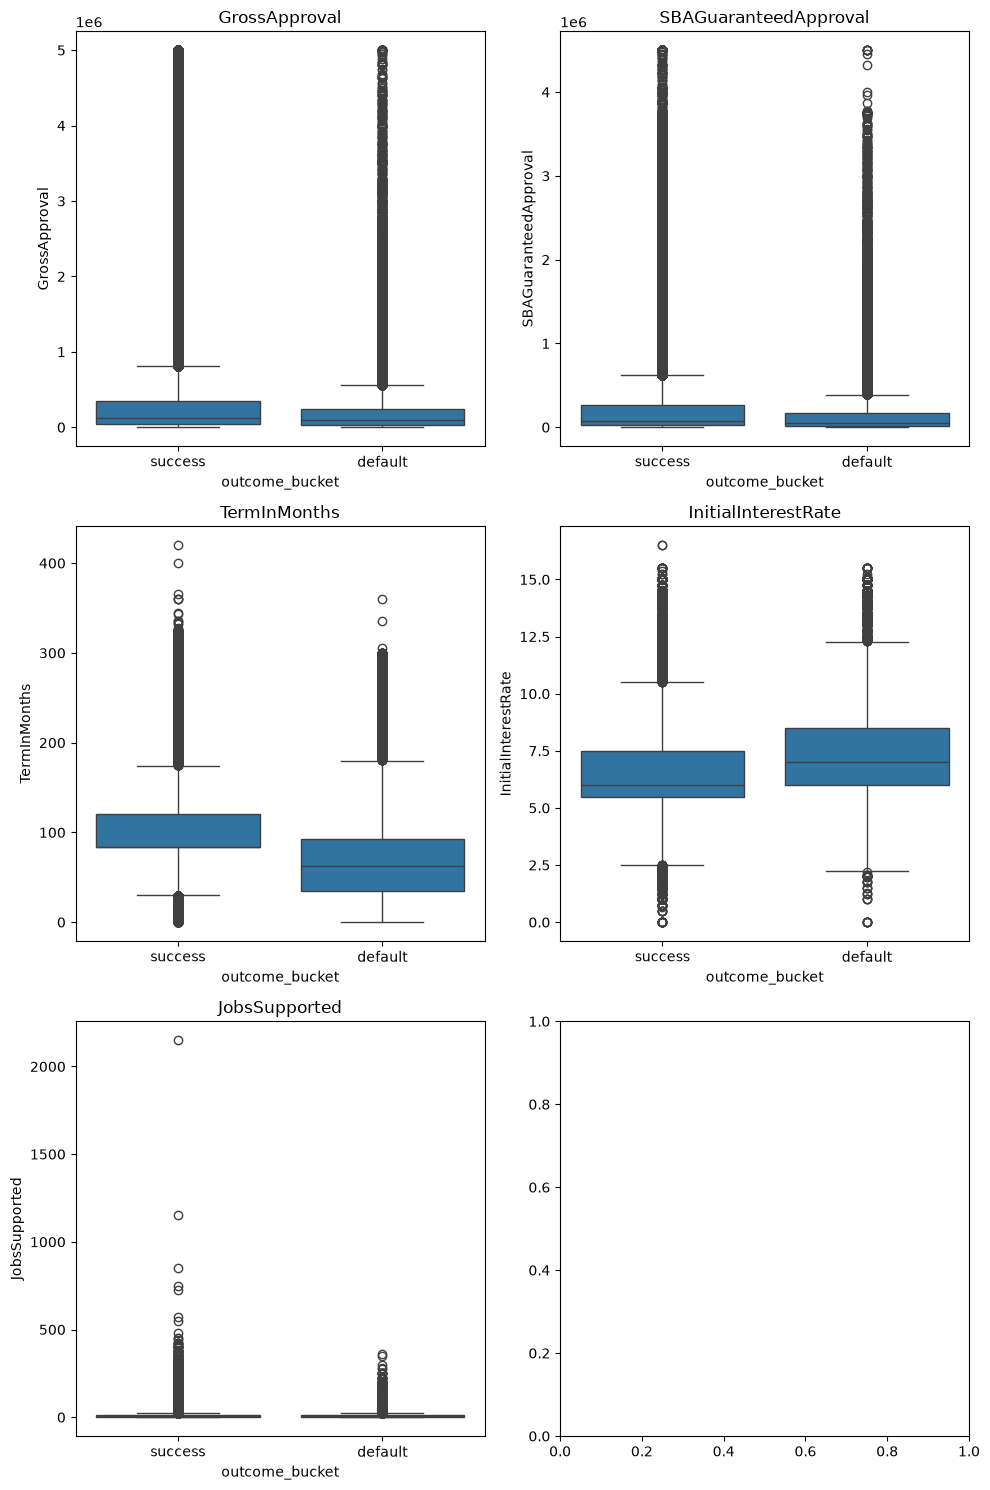

outcome_bucket                    default       success
GrossApproval         count  4.104600e+04  4.629220e+05
                      mean   2.368111e+05  3.796001e+05
                      std    4.702432e+05  6.958614e+05
                      min    2.000000e+03  1.000000e+03
                      25%    2.500000e+04  4.000000e+04
                      50%    1.000000e+05  1.170000e+05
                      75%    2.385750e+05  3.500000e+05
                      max    5.000000e+06  5.000000e+06
SBAGuaranteedApproval count  4.104600e+04  4.629220e+05
                      mean   1.767796e+05  2.829605e+05
                      std    3.662749e+05  5.404232e+05
                      min    1.000000e+03  5.000000e+02
                      25%    1.500000e+04  2.100000e+04
                      50%    5.000000e+04  7.500000e+04
                      75%    1.650000e+05  2.625000e+05
                      max    4.500000e+06  4.500000e+06
TermInMonths          count  4.104600e+04  4.629220e+05
                      mean   6.852724e+01  1.199916e+02
                      std    4.865953e+01  7.597538e+01
                      min    0.000000e+00  0.000000e+00
                      25%    3.500000e+01  8.400000e+01
                      50%    6.300000e+01  8.400000e+01
                      75%    9.300000e+01  1.200000e+02
                      max    3.600000e+02  4.200000e+02
InitialInterestRate   count  4.104600e+04  4.629220e+05
                      mean   7.424951e+00  6.570563e+00
                      std    2.037096e+00  1.716822e+00
                      min    0.000000e+00  0.000000e+00
                      25%    6.000000e+00  5.500000e+00
                      50%    7.000000e+00  6.000000e+00
                      75%    8.500000e+00  7.500000e+00
                      max    1.550000e+01  1.650000e+01
JobsSupported         count  4.104600e+04  4.629220e+05
                      mean   8.928982e+00  1.078391e+01
                      std    1.637858e+01  2.079585e+01
                      min    0.000000e+00  0.000000e+00
                      25%    2.000000e+00  2.000000e+00
                      50%    4.000000e+00  4.000000e+00
                      75%    1.000000e+01  1.100000e+01
                      max    3.620000e+02  2.150000e+03

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = ['GrossApproval', 'SBAGuaranteedApproval', 'TermInMonths', 'InitialInterestRate', 'JobsSupported']

fig, axes = plt.subplots(3, 2, figsize=(10, 15))
for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(data=df_model, x='outcome_bucket', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Quick numeric summary alongside the plots
df_model.groupby('outcome_bucket')[numeric_features].describe().T

In [18]:
df_model.groupby('outcome_bucket')[numeric_features].describe().T.to_clipboard(index=True)

c:\Users\Mason\OneDrive\Desktop\smb_loan\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\Mason\OneDrive\Desktop\smb_loan\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\Mason\OneDrive\Desktop\smb_loan\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\Mason\OneDrive\Desktop\smb_loan\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\Mason\OneDrive\Desktop\smb_loan\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)


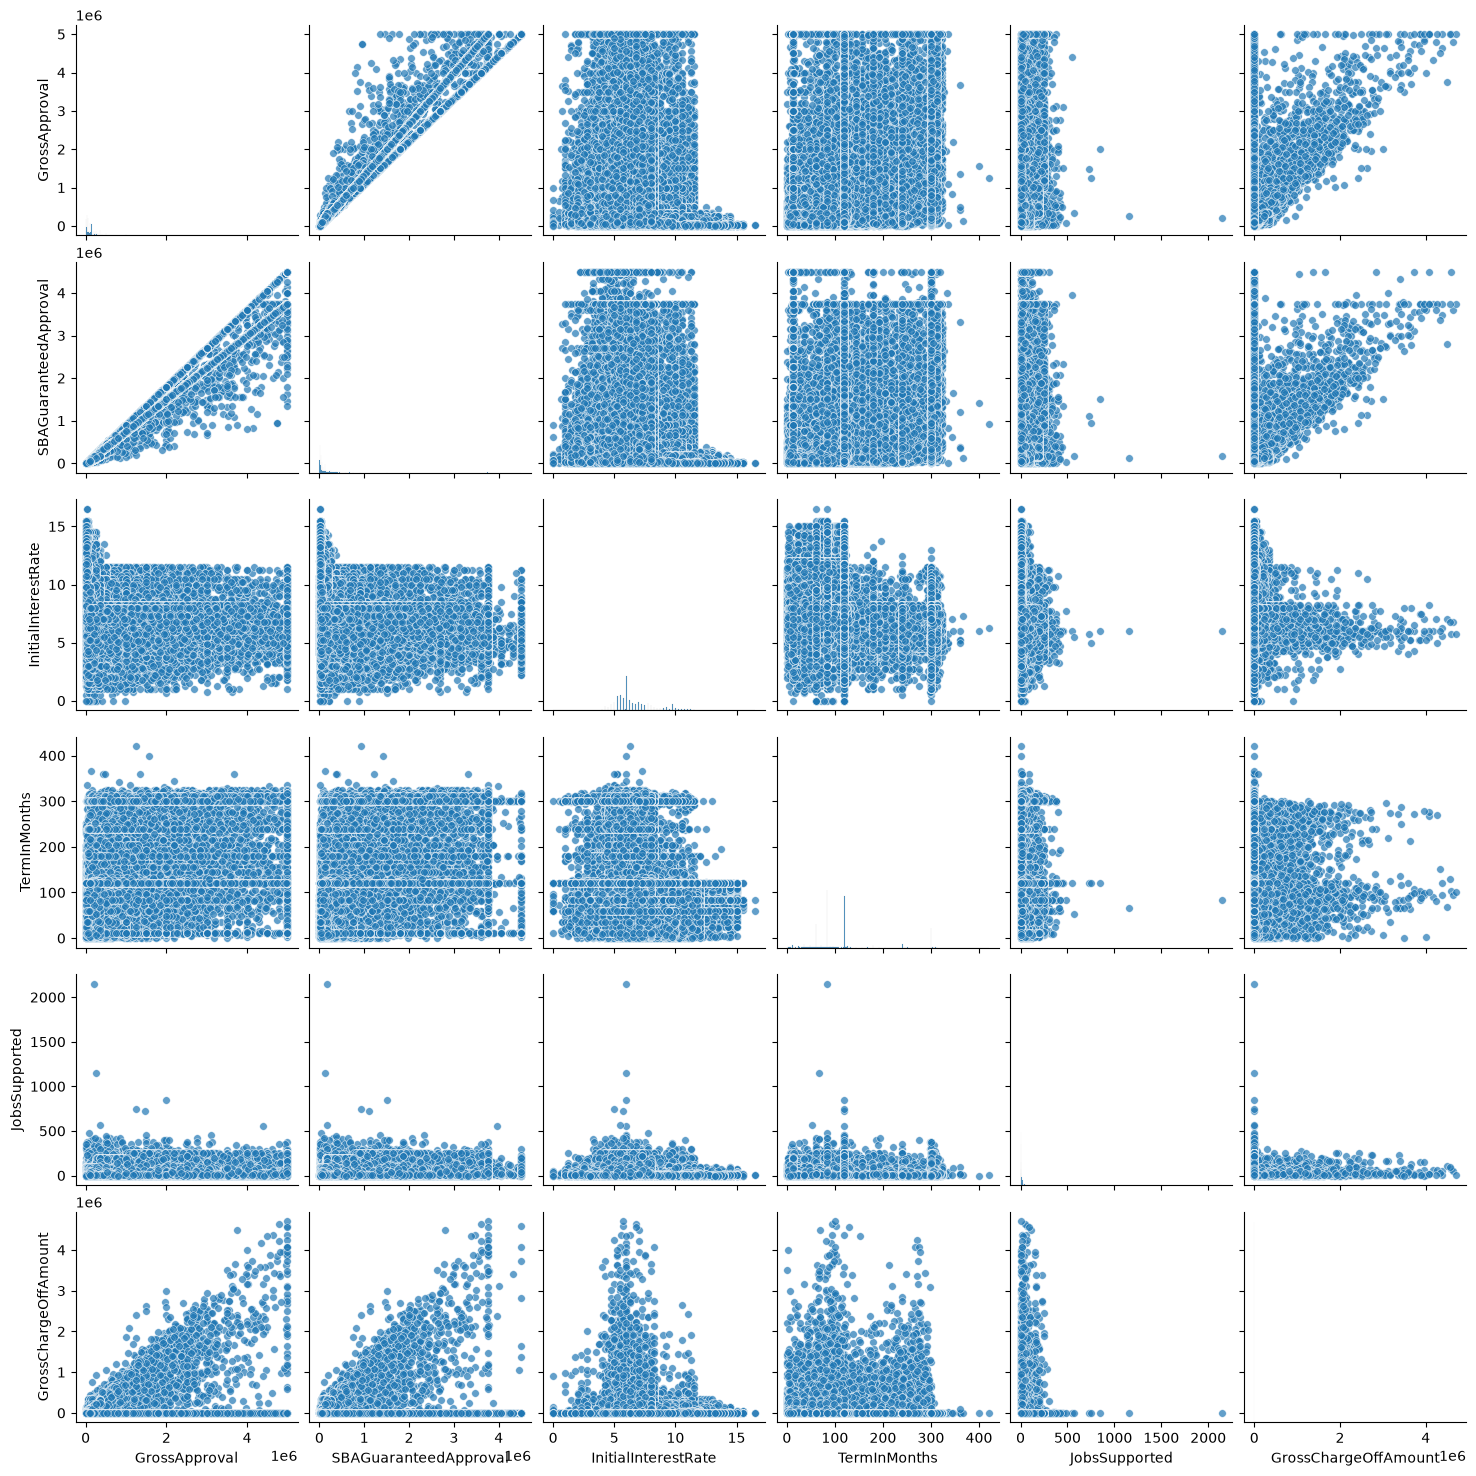

In [19]:
df_pair = df_model[['GrossApproval','SBAGuaranteedApproval','InitialInterestRate','TermInMonths','JobsSupported','GrossChargeOffAmount']]
sns.pairplot(
    data=df_pair,
    palette='Set2',
    plot_kws={'alpha':0.7, 's':30},
    diag_kws={'common_norm':False})
plt.show()

### visualization 3

NAICS sector + geography charts

In [20]:
naics_sectors = {
    '11': 'Agriculture, Forestry, Fishing and Hunting',
    '21': 'Mining, Quarrying, and Oil and Gas Extraction',
    '22': 'Utilities',
    '23': 'Construction',
    '31': 'Manufacturing', '32': 'Manufacturing', '33': 'Manufacturing',
    '42': 'Wholesale Trade',
    '44': 'Retail Trade', '45': 'Retail Trade',
    '48': 'Transportation and Warehousing', '49': 'Transportation and Warehousing',
    '51': 'Information',
    '52': 'Finance and Insurance',
    '53': 'Real Estate and Rental and Leasing',
    '54': 'Professional, Scientific, and Technical Services',
    '55': 'Management of Companies and Enterprises',
    '56': 'Administrative and Support and Waste Management',
    '61': 'Educational Services',
    '62': 'Health Care and Social Assistance',
    '71': 'Arts, Entertainment, and Recreation',
    '72': 'Accommodation and Food Services',
    '81': 'Other Services (except Public Administration)',
    '92': 'Public Administration',
}
naics_code_str = df_model['NaicsCode'].astype('Int64').astype(str).str.zfill(6)
df_model['naics_2digit'] = naics_code_str.str[:2]
df_model['naics_sector'] = df_model['naics_2digit'].map(naics_sectors)

print(df_model.loc[df_model['naics_sector'].isna(), 'naics_2digit'].value_counts())



Series([], Name: count, dtype: int64)


In [21]:
sector_summary = df_model.groupby('naics_sector').agg(
    n=('target', 'size'),
    default_rate=('target', lambda x: 1 - x.mean())
).sort_values('n', ascending=False)


print(sector_summary)

                                                      n  default_rate
naics_sector                                                         
Retail Trade                                      67748      0.091604
Accommodation and Food Services                   63587      0.087486
Construction                                      56214      0.087772
Professional, Scientific, and Technical Services  50017      0.074175
Health Care and Social Assistance                 45119      0.052661
Other Services (except Public Administration)     43488      0.083356
Manufacturing                                     39134      0.068380
Transportation and Warehousing                    29482      0.106743
Wholesale Trade                                   26854      0.093617
Administrative and Support and Waste Management   24395      0.083050
Arts, Entertainment, and Recreation               14489      0.105183
Real Estate and Rental and Leasing                11254      0.062111
Finance and Insuranc

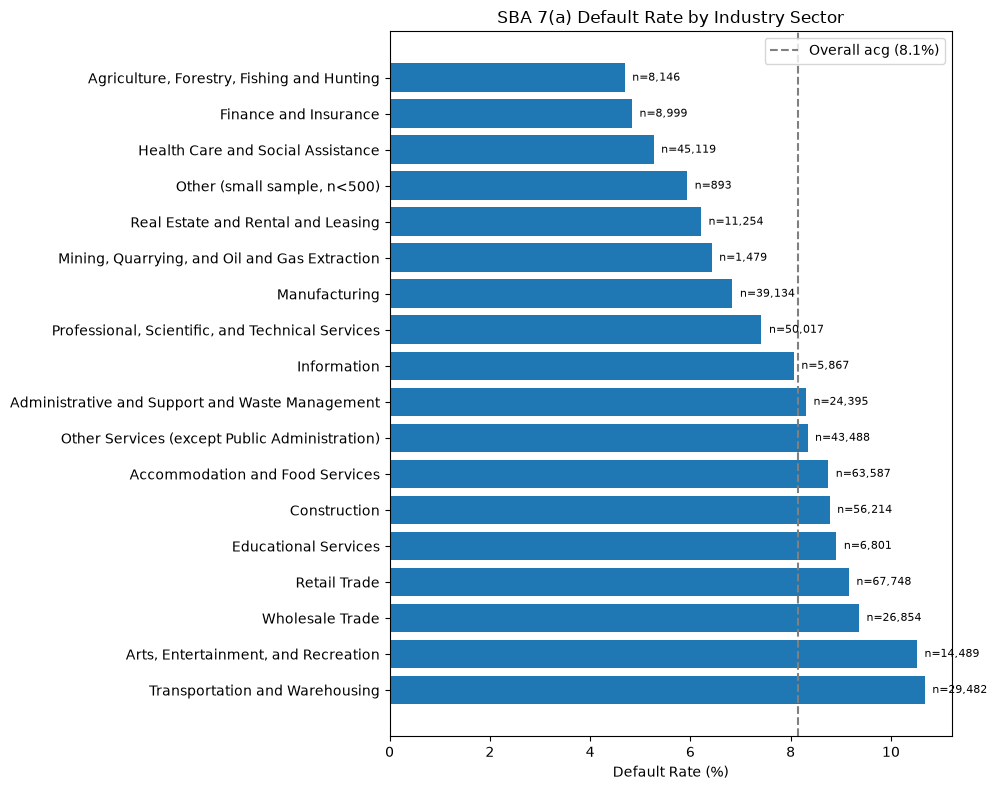

In [ ]:
threshold = 500
reliable = sector_summary[sector_summary['n'] >= threshold].copy()
small = sector_summary[sector_summary['n'] < threshold]

other_row = pd.DataFrame({
    'n': [small['n'].sum()],
    'default_rate': [(small['n'] * small['default_rate']).sum() / small['n'].sum()]
}, index=['Other (small sample, n<500)'])

plot_data = pd.concat([reliable, other_row]).sort_values('default_rate', ascending=False)

fig, ax = plt.subplots(figsize=(10,8))
bars = ax.barh(plot_data.index, plot_data['default_rate'] * 100)
ax.axvline(41046/503968 * 100, color='gray',linestyle='--', label='Overall acg (8.1%)')
ax.set_xlabel('Default Rate (%)')
ax.set_title('SBA 7(a) Default Rate by Industry Sector')
ax.legend()

for bar, n in zip(bars, plot_data['n']):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f'n={n:,}', va='center',fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
state_summary = df_model.groupby('ProjectState').agg(
    n=('target', 'size'),
    default_rate=('target', lambda x: 1 - x.mean())
).sort_values('default_rate', ascending=False)
print(state_summary)

                  n  default_rate
ProjectState                     
MP                5      0.200000
FL            25166      0.127553
DC              786      0.117048
NJ            13459      0.113084
NY            31759      0.106332
TX            37546      0.104991
LA             3729      0.104318
DE             1361      0.101396
SC             4013      0.100424
MD             7106      0.100056
NV             4009      0.098778
IL            16457      0.097162
VA             7602      0.096685
AL             3436      0.096333
VI               88      0.090909
GA            13408      0.088082
MO             9463      0.087182
TN             4693      0.086299
MS             4340      0.085714
CA            60619      0.082103
CT             5575      0.081973
OK             4592      0.081010
IA             4128      0.079700
AR             2927      0.079604
KY             4694      0.077759
NC             9960      0.076606
HI             2815      0.076021
AZ            

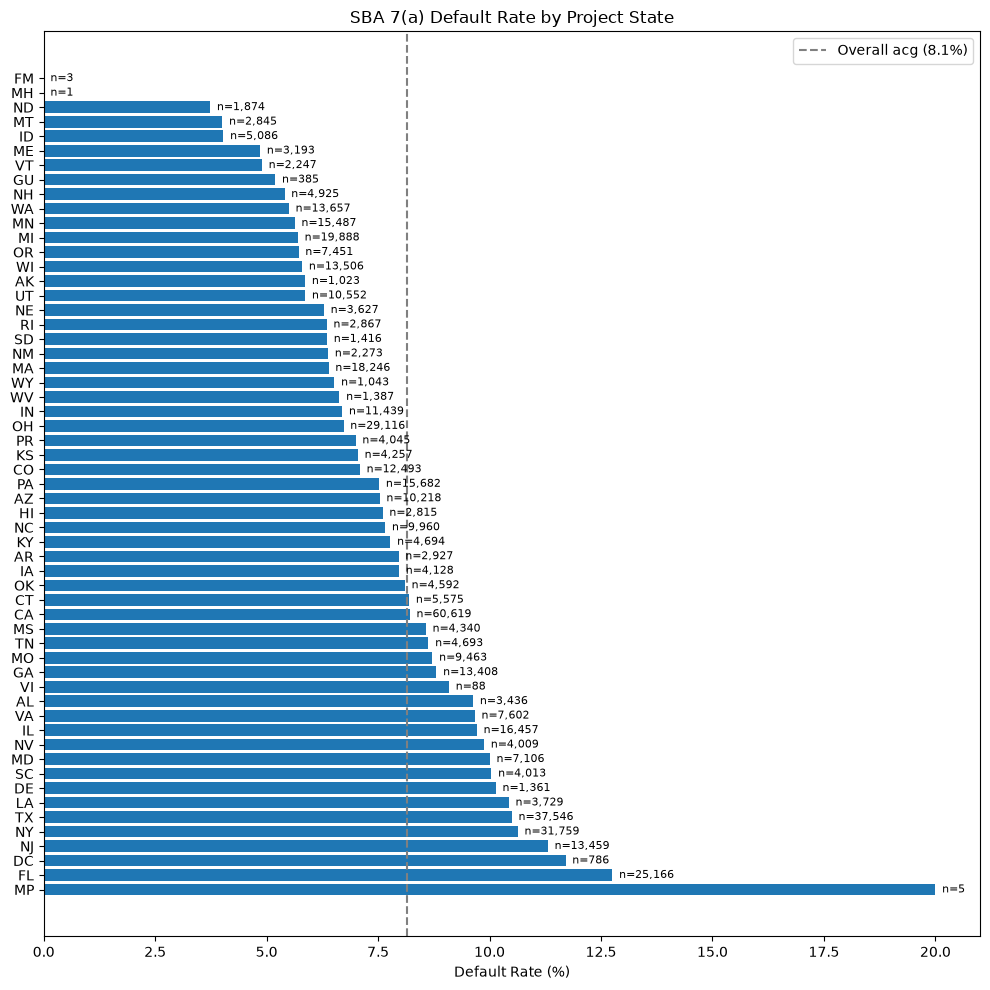

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
bars = ax.barh(state_summary.index, state_summary['default_rate'] * 100)
ax.axvline(41046/503968 * 100, color='gray',linestyle='--', label='Overall acg (8.1%)')
ax.set_xlabel('Default Rate (%)')
ax.set_title('SBA 7(a) Default Rate by Project State')
ax.legend()

for bar, n in zip(bars, state_summary['n']):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f'n={n:,}', va='center',fontsize=8)
plt.tight_layout()
plt.show()

                                       n  default_rate
BusinessAge                                           
StartupLoanFundswillOpenBusiness   74865      0.096841
NewLessthan1Yearold                42936      0.087759
NewBusinessor2yearsorless          12744      0.138026
Lessthan3yearsoldbutatleast2       23612      0.091733
Lessthan4yearsoldbutatleast3       28010      0.078543
Lessthan5yearsoldbutatleast4       17402      0.085507
Existing5ormoreyears              174326      0.062693
Existingormorethan2yearsold        74347      0.091907
ChangeofOwnership                  13613      0.056857
Unanswered                         40770      0.080819


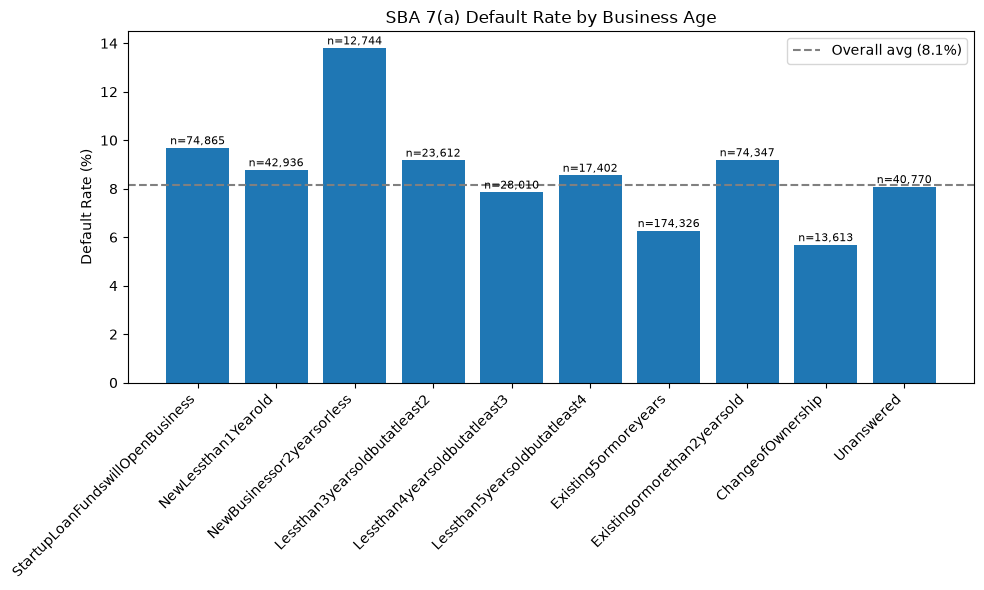

In [ ]:
business_age_order = [
    'StartupLoanFundswillOpenBusiness',
    'NewLessthan1Yearold',
    'NewBusinessor2yearsorless',
    'Lessthan3yearsoldbutatleast2',
    'Lessthan4yearsoldbutatleast3',
    'Lessthan5yearsoldbutatleast4',
    'Existing5ormoreyears',
    'Existingormorethan2yearsold',  # see note below
    'ChangeofOwnership',
    'Unanswered',
]

age_summary = df_model.groupby('BusinessAge').agg(
    n=('target', 'size'),
    default_rate=('target', lambda x: 1 - x.mean())
).reindex(business_age_order)

print(age_summary)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(age_summary.index, age_summary['default_rate'] * 100)
ax.axhline(41046/503968 * 100, color='gray', linestyle='--', label='Overall avg (8.1%)')
ax.set_ylabel('Default Rate (%)')
ax.set_title('SBA 7(a) Default Rate by Business Age')
plt.xticks(rotation=45, ha='right')
ax.legend()

for bar, n in zip(bars, age_summary['n']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15, f'n={n:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

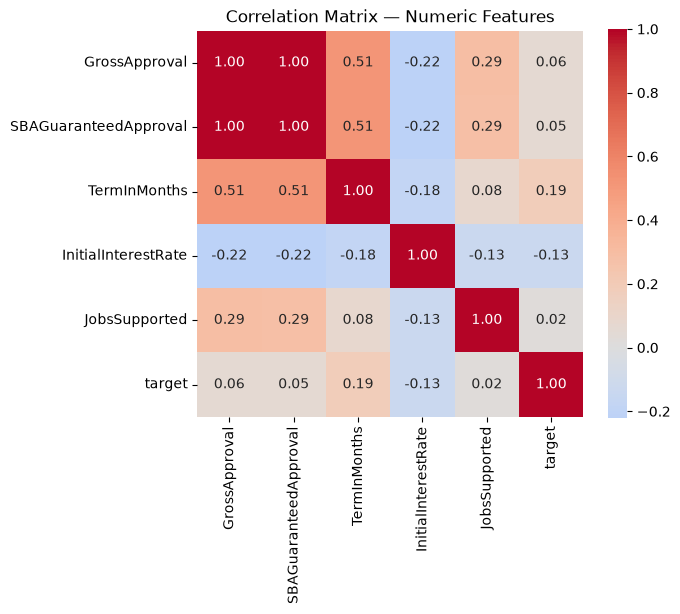

In [ ]:
numeric_features = ['GrossApproval', 'SBAGuaranteedApproval', 'TermInMonths', 'InitialInterestRate', 'JobsSupported', 'target']

corr = df_model[numeric_features].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix — Numeric Features')
plt.tight_layout()
plt.show()

In [ ]:
df.columns.to